In [1]:
from google.colab import files

uploaded = files.upload()

Saving Data_Failure_Candidates.zip to Data_Failure_Candidates.zip


In [2]:
import zipfile
import os
import shutil

zip_file = list(uploaded.keys())[0]

extract_dir = "/content/figure4_data"

if os.path.exists(extract_dir):
    shutil.rmtree(extract_dir)

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("ZIP extracted successfully.")

ZIP extracted successfully.


In [3]:
import os

original_dir = None
enhanced_dir = None

for root, dirs, files in os.walk(extract_dir):

    for d in dirs:
        if d.lower() == "original":
            original_dir = os.path.join(root, d)

        if d.lower() == "enhanced":
            enhanced_dir = os.path.join(root, d)

print("Original folder :", original_dir)
print("Enhanced folder:", enhanced_dir)

Original folder : /content/figure4_data/Data_Failure_Candidates/Original
Enhanced folder: /content/figure4_data/Data_Failure_Candidates/Enhanced


In [4]:
selected_cases = [
    ("a", "Bract-Mosaic-Virus-Disease-189"),
    ("b", "Bract-Mosaic-Virus-Disease-60"),
    ("c", "Yellow-and-Black-Sigatoka-1658")
]

print("Selected cases:")
for label, name in selected_cases:
    print(f"({label}) {name}")

Selected cases:
(a) Bract-Mosaic-Virus-Disease-189
(b) Bract-Mosaic-Virus-Disease-60
(c) Yellow-and-Black-Sigatoka-1658


In [5]:
def find_image(folder, keyword):

    valid_extensions = (
        ".jpg",
        ".jpeg",
        ".png",
        ".webp"
    )

    matches = []

    for filename in os.listdir(folder):

        if not filename.lower().endswith(valid_extensions):
            continue

        if keyword.lower() in filename.lower():
            matches.append(os.path.join(folder, filename))

    if len(matches) == 0:
        return None

    if len(matches) > 1:
        print("Warning: multiple matches found for:", keyword)
        for m in matches:
            print("   ", os.path.basename(m))

    return matches[0]


pairs = []

for label, keyword in selected_cases:

    original_path = find_image(
        original_dir,
        keyword
    )

    enhanced_path = find_image(
        enhanced_dir,
        keyword
    )

    if original_path is None:
        print("ERROR: Original image not found:", keyword)

    if enhanced_path is None:
        print("ERROR: Enhanced image not found:", keyword)

    if original_path and enhanced_path:

        pairs.append(
            (
                label,
                keyword,
                original_path,
                enhanced_path
            )
        )

print("\nVerified pairs:")
for label, keyword, original_path, enhanced_path in pairs:

    print("\n", label, keyword)
    print("Original :", os.path.basename(original_path))
    print("Enhanced :", os.path.basename(enhanced_path))


Verified pairs:

 a Bract-Mosaic-Virus-Disease-189
Original : Bract-Mosaic-Virus-Disease-189.jpg
Enhanced : Bract-Mosaic-Virus-Disease-189.jpg

 b Bract-Mosaic-Virus-Disease-60
Original : Bract-Mosaic-Virus-Disease-60.jpg
Enhanced : Bract-Mosaic-Virus-Disease-60.jpg

 c Yellow-and-Black-Sigatoka-1658
Original : Yellow-and-Black-Sigatoka-1658.jpg
Enhanced : Yellow-and-Black-Sigatoka-1658.jpg


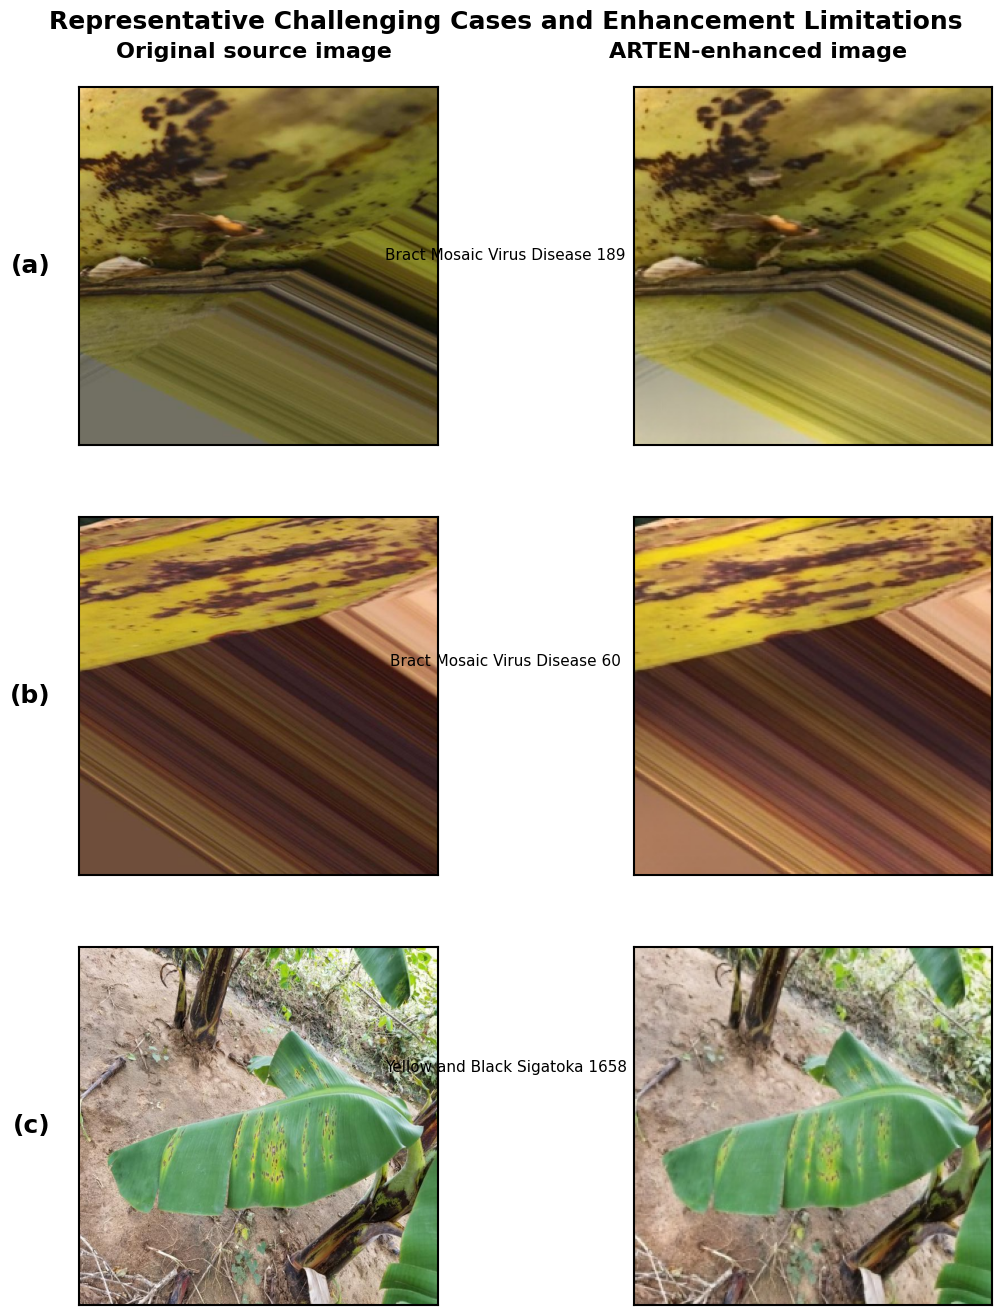


Figure generated successfully:
/content/Figure_4_ARTEN_Challenging_Cases.png
/content/Figure_4_ARTEN_Challenging_Cases.pdf
/content/Figure_4_ARTEN_Challenging_Cases.tiff


In [6]:
from PIL import Image, ImageOps, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import os

# ============================================================
# PUBLICATION FIGURE SETTINGS
# ============================================================

FIG_WIDTH = 12
FIG_HEIGHT = 14

# Create figure
fig = plt.figure(
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    facecolor="white"
)

# Grid:
# 3 rows × 2 columns
# Left  = Original
# Right = ARTEN-enhanced

gs = fig.add_gridspec(
    nrows=3,
    ncols=2,
    left=0.08,
    right=0.97,
    top=0.93,
    bottom=0.06,
    wspace=0.08,
    hspace=0.20
)

# ============================================================
# COLUMN HEADINGS
# ============================================================

fig.text(
    0.29,
    0.955,
    "Original source image",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold"
)

fig.text(
    0.71,
    0.955,
    "ARTEN-enhanced image",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold"
)

# ============================================================
# CASE LABELS
# ============================================================

case_labels = {
    "a": "Bract Mosaic Virus Disease 189",
    "b": "Bract Mosaic Virus Disease 60",
    "c": "Yellow and Black Sigatoka 1658"
}

# ============================================================
# PLOT EACH ORIGINAL / ENHANCED PAIR
# ============================================================

for row, (label, keyword, original_path, enhanced_path) in enumerate(pairs):

    # --------------------------------------------------------
    # ORIGINAL
    # --------------------------------------------------------

    ax_original = fig.add_subplot(gs[row, 0])

    original_img = Image.open(
        original_path
    ).convert("RGB")

    ax_original.imshow(original_img)

    ax_original.set_xticks([])
    ax_original.set_yticks([])

    # Border
    for spine in ax_original.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.5)

    # --------------------------------------------------------
    # ENHANCED
    # --------------------------------------------------------

    ax_enhanced = fig.add_subplot(gs[row, 1])

    enhanced_img = Image.open(
        enhanced_path
    ).convert("RGB")

    ax_enhanced.imshow(enhanced_img)

    ax_enhanced.set_xticks([])
    ax_enhanced.set_yticks([])

    # Border
    for spine in ax_enhanced.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.5)

    # --------------------------------------------------------
    # CASE LABEL
    # --------------------------------------------------------

    ax_original.text(
        -0.08,
        0.5,
        f"({label})",
        transform=ax_original.transAxes,
        fontsize=18,
        fontweight="bold",
        ha="right",
        va="center"
    )

    # --------------------------------------------------------
    # IMAGE CATEGORY LABEL
    # --------------------------------------------------------

    fig.text(
        0.50,
        0.955 - ((row + 0.5) / 3) * 0.87,
        case_labels[label],
        ha="center",
        va="center",
        fontsize=11
    )

# ============================================================
# MAIN FIGURE TITLE
# ============================================================

fig.suptitle(
    "Representative Challenging Cases and Enhancement Limitations",
    fontsize=18,
    fontweight="bold",
    y=0.985
)

# ============================================================
# SAVE FIGURE
# ============================================================

output_png = "/content/Figure_4_ARTEN_Challenging_Cases.png"

output_pdf = "/content/Figure_4_ARTEN_Challenging_Cases.pdf"

output_tiff = "/content/Figure_4_ARTEN_Challenging_Cases.tiff"

plt.savefig(
    output_png,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    output_pdf,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    output_tiff,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nFigure generated successfully:")
print(output_png)
print(output_pdf)
print(output_tiff)

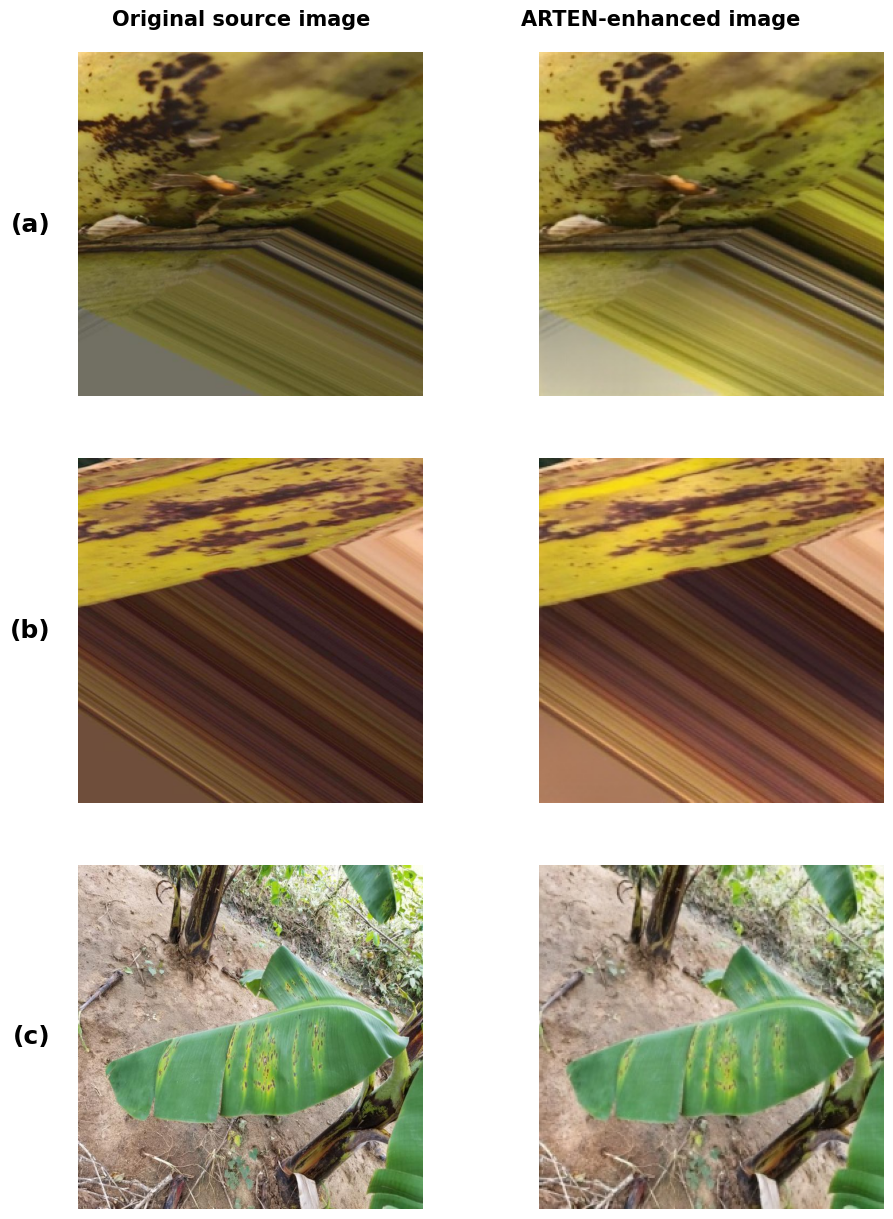

DONE


In [7]:
import matplotlib.pyplot as plt
from PIL import Image

fig = plt.figure(
    figsize=(10, 13),
    facecolor="white"
)

gs = fig.add_gridspec(
    3,
    2,
    left=0.08,
    right=0.98,
    top=0.94,
    bottom=0.05,
    wspace=0.05,
    hspace=0.18
)

# Column headings
fig.text(
    0.29,
    0.965,
    "Original source image",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

fig.text(
    0.71,
    0.965,
    "ARTEN-enhanced image",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

for row, (label, keyword, original_path, enhanced_path) in enumerate(pairs):

    # Original
    ax1 = fig.add_subplot(gs[row, 0])

    img1 = Image.open(original_path).convert("RGB")

    ax1.imshow(img1)
    ax1.axis("off")

    for spine in ax1.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.5)

    # Enhanced
    ax2 = fig.add_subplot(gs[row, 1])

    img2 = Image.open(enhanced_path).convert("RGB")

    ax2.imshow(img2)
    ax2.axis("off")

    for spine in ax2.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.5)

    # Case label
    ax1.text(
        -0.08,
        0.5,
        f"({label})",
        transform=ax1.transAxes,
        fontsize=18,
        fontweight="bold",
        ha="right",
        va="center"
    )

# Save publication files

plt.savefig(
    "/content/Figure_4_ARTEN_Challenging_Cases_Final.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "/content/Figure_4_ARTEN_Challenging_Cases_Final.pdf",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "/content/Figure_4_ARTEN_Challenging_Cases_Final.tiff",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("DONE")